In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_FILE = PROJECT_ROOT / "data/raw/synthetic_financial/synthetic_financial.csv"
if not DATA_FILE.exists():
    DATA_FILE = PROJECT_ROOT / "data/raw/synthetic_financial/cleaned_data.csv"

RANDOM_STATE = 42
PLOT_SAMPLE_SIZE = 100_000
PAIRPLOT_SAMPLE_SIZE = 2_000
SCATTER_SAMPLE_SIZE = 20_000

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv(DATA_FILE)
print(f"Loaded: {DATA_FILE}")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
print(f"Fraud cases: {int(df['isFraud'].sum()):,} ({df['isFraud'].mean() * 100:.4f}%)")

plot_df = df.sample(min(PLOT_SAMPLE_SIZE, len(df)), random_state=RANDOM_STATE) if len(df) > PLOT_SAMPLE_SIZE else df.copy()
scatter_df = df.sample(min(SCATTER_SAMPLE_SIZE, len(df)), random_state=RANDOM_STATE) if len(df) > SCATTER_SAMPLE_SIZE else df.copy()
pairplot_df = df.sample(min(PAIRPLOT_SAMPLE_SIZE, len(df)), random_state=RANDOM_STATE) if len(df) > PAIRPLOT_SAMPLE_SIZE else df.copy()

Loaded: /Users/youseftahoon/DEPI Project/data/raw/synthetic_financial/synthetic_financial.csv
Shape: 6,362,620 rows x 11 columns
Fraud cases: 8,213 (0.1291%)


In [3]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


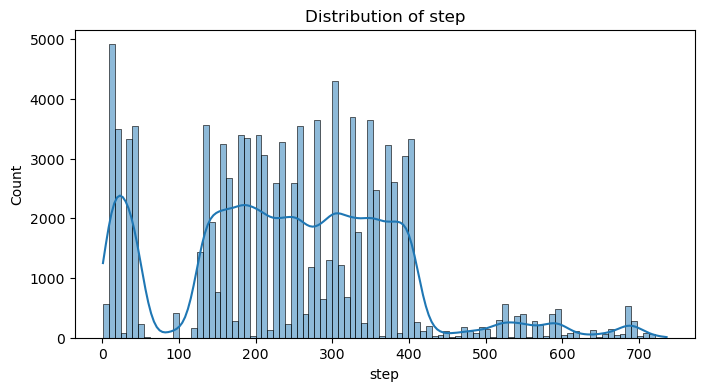

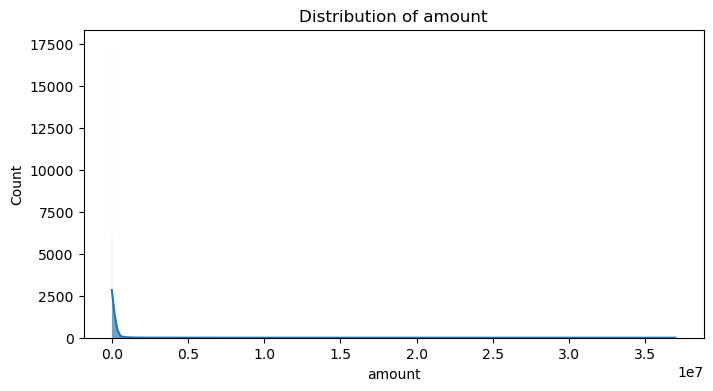

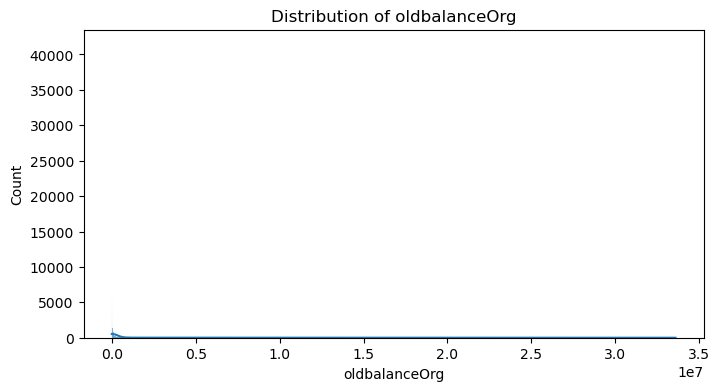

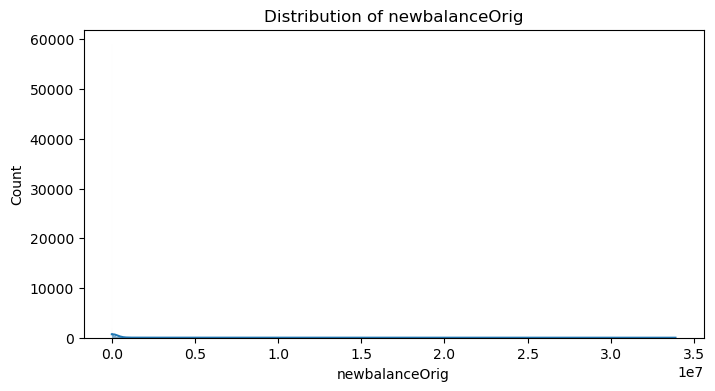

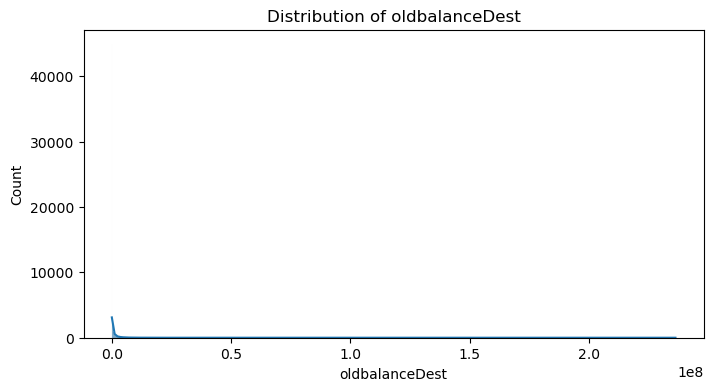

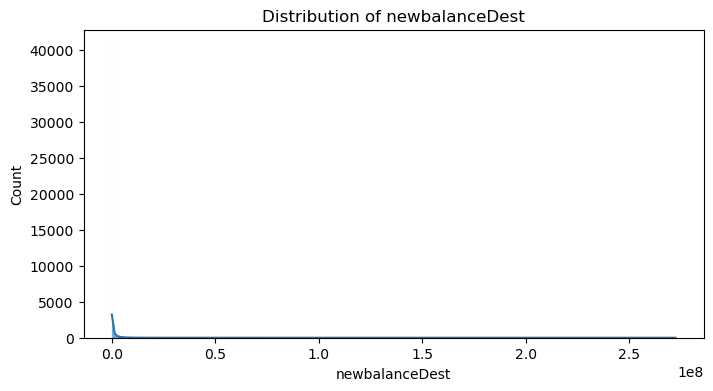

In [4]:
numerical_cols = [
    'step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest'
]

for col in numerical_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(plot_df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()

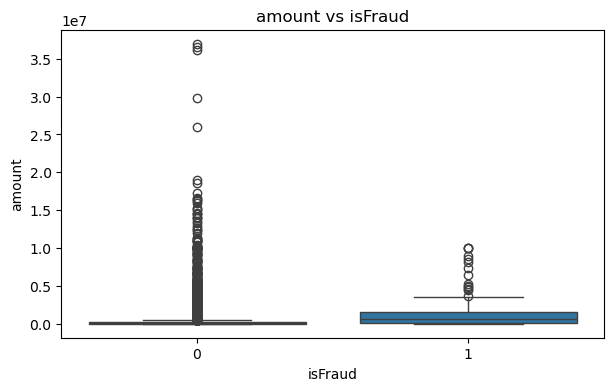

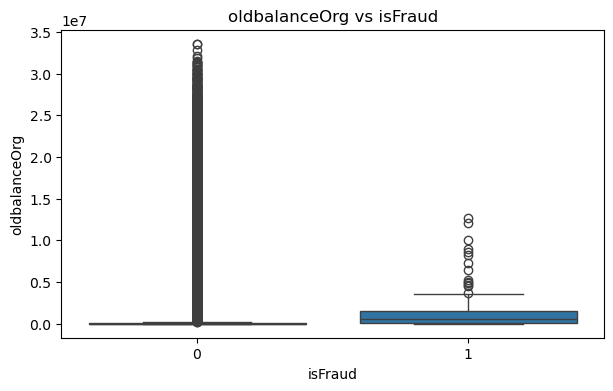

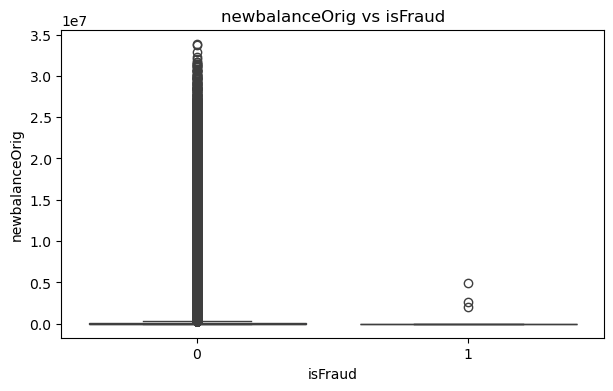

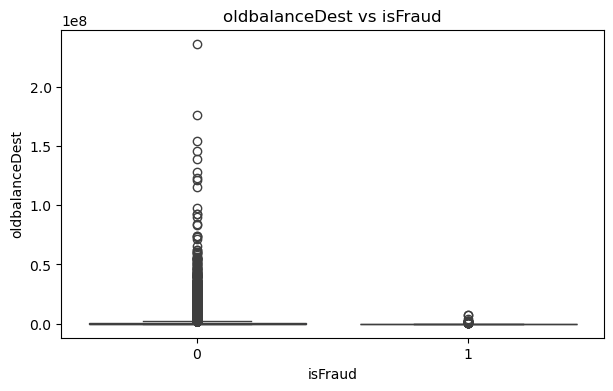

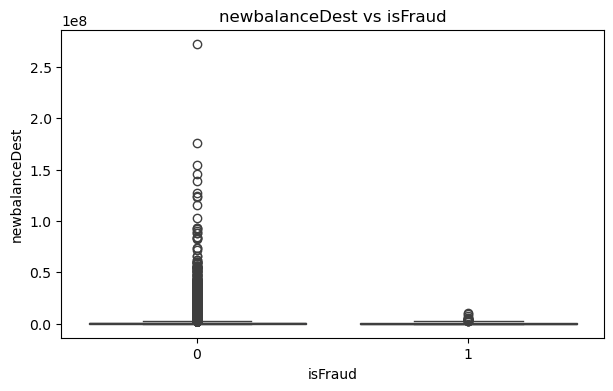

In [5]:
cols = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']

for col in cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x='isFraud', y=col, data=plot_df)
    plt.title(f'{col} vs isFraud')
    plt.show()

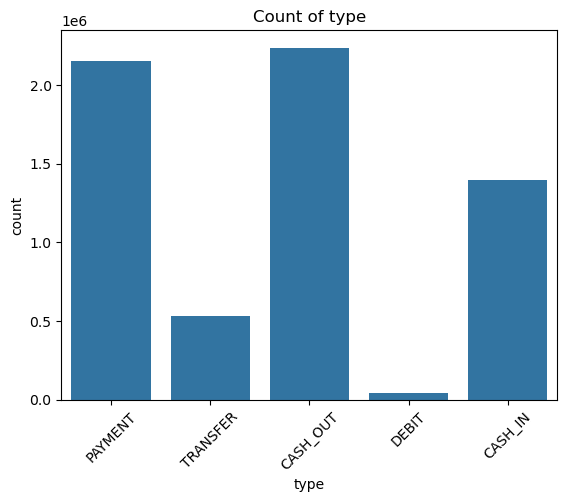

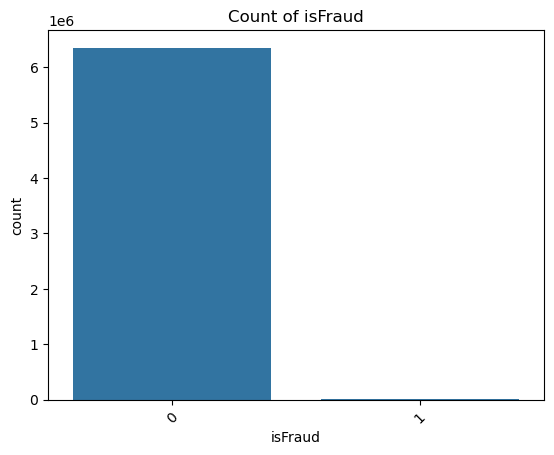

In [6]:
cat_cols = ['type', 'isFraud']

for col in cat_cols:
    plt.figure()
    sns.countplot(x=col, data=df)
    plt.title(f'Count of {col}')
    plt.xticks(rotation=45)
    plt.show()

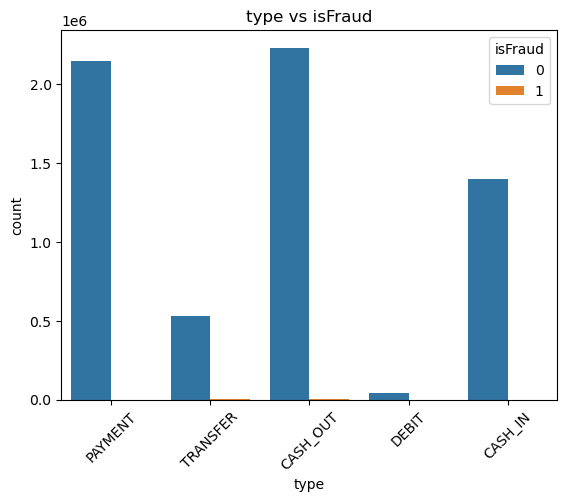

In [7]:
cols = ['type']

for col in cols:
    plt.figure()
    sns.countplot(x=col, hue='isFraud', data=df)
    plt.title(f'{col} vs isFraud')
    plt.xticks(rotation=45)
    plt.show()

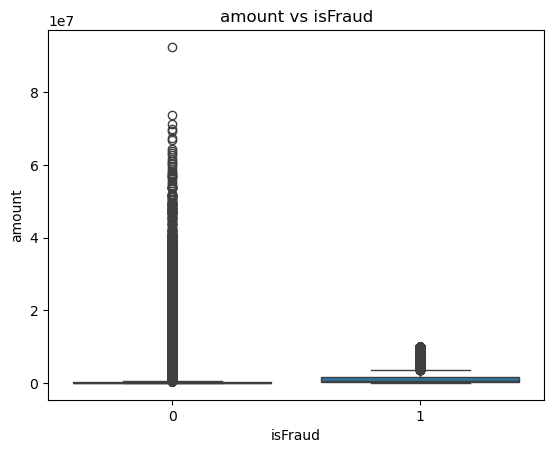

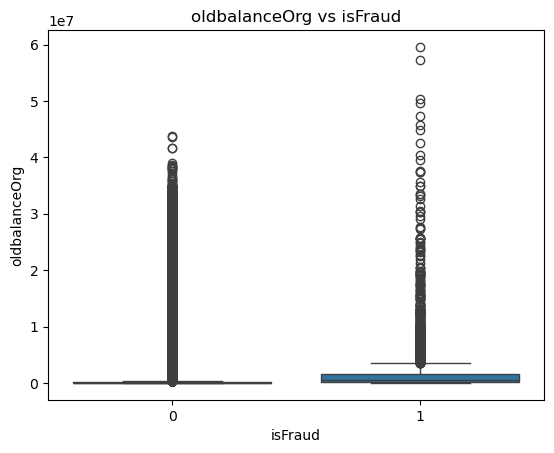

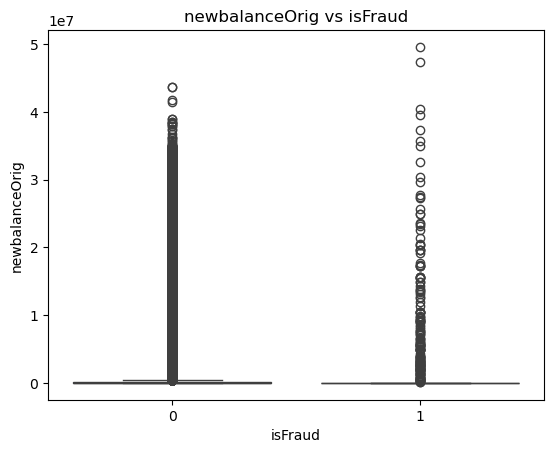

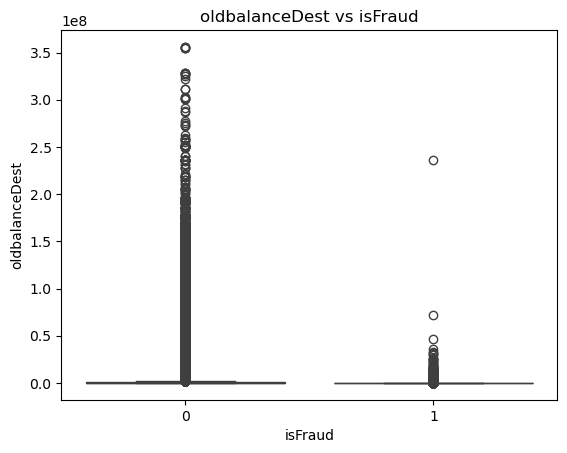

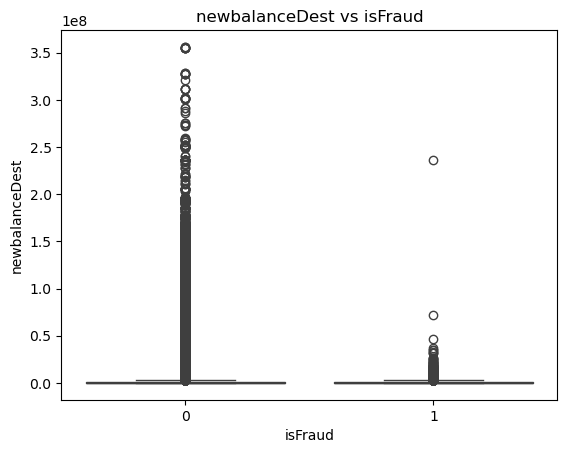

In [8]:
cols = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']

for col in cols:
    plt.figure()
    sns.boxplot(x='isFraud', y=col, data=df)
    plt.title(f'{col} vs isFraud')
    plt.show()

In [9]:
cols = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']

outlier_rows = []
iqr_mask = pd.Series(True, index=df.index)
for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    col_mask = (df[col] >= lower_bound) & (df[col] <= upper_bound)
    outlier_rows.append({
        "feature": col,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": int((~col_mask).sum()),
        "outlier_rate_%": round((~col_mask).mean() * 100, 4),
    })
    iqr_mask &= col_mask

outlier_summary = pd.DataFrame(outlier_rows)
df_iqr = df.loc[iqr_mask]
df_iqr_plot = df_iqr.sample(min(PLOT_SAMPLE_SIZE, len(df_iqr)), random_state=RANDOM_STATE) if len(df_iqr) > PLOT_SAMPLE_SIZE else df_iqr.copy()
print(f"Rows after applying combined IQR mask for visualization only: {len(df_iqr):,}")
outlier_summary

Rows after applying combined IQR mask for visualization only: 4,393,187


,feature,lower_bound,upper_bound,outlier_count,outlier_rate_%
0,amount,-2.796083e+05,5.017193e+05,338078,5.3135
1,oldbalanceOrg,-1.609728e+05,2.682879e+05,1112507,17.4850
2,newbalanceOrig,-2.163876e+05,3.606460e+05,1053391,16.5559
3,oldbalanceDest,-1.414555e+06,2.357592e+06,786135,12.3555
4,newbalanceDest,-1.667864e+06,2.779773e+06,738527,11.6073


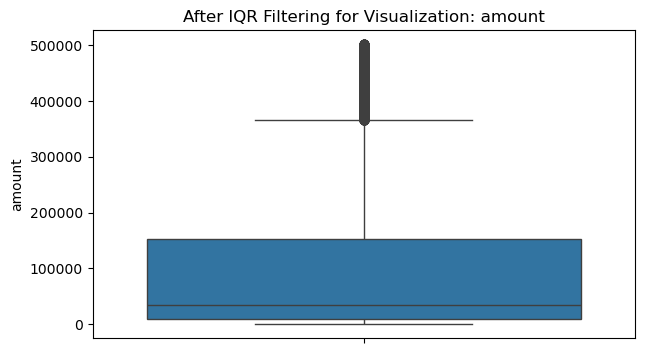

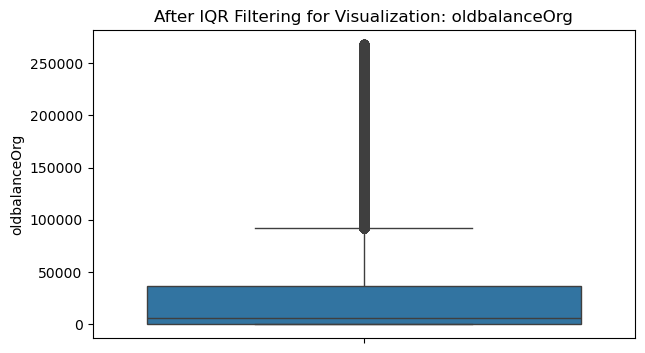

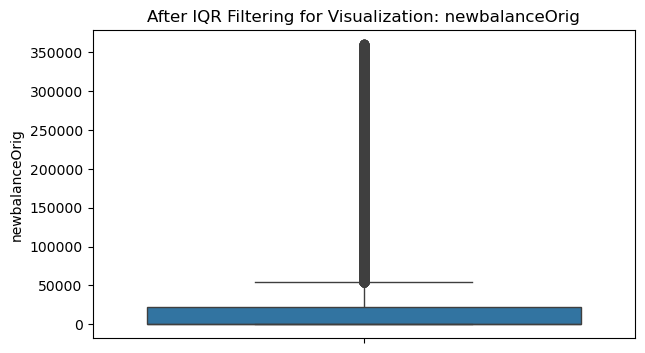

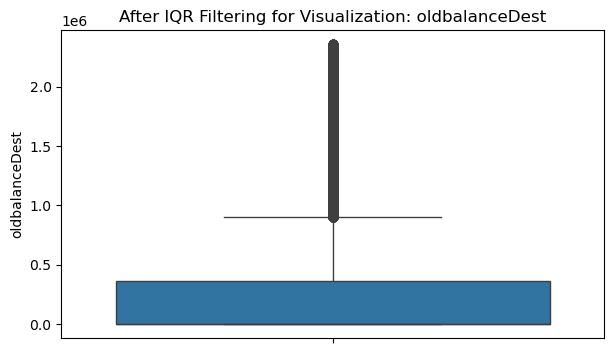

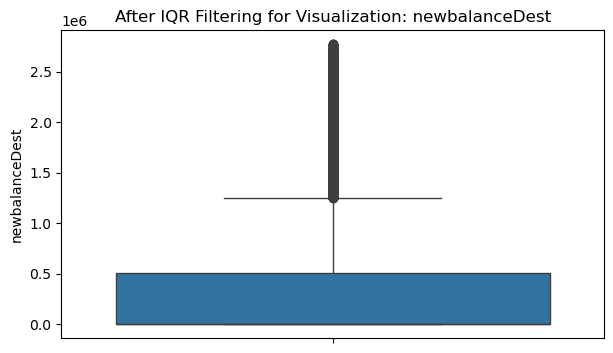

In [10]:
cols = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']

for col in cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(y=df_iqr_plot[col])
    plt.title(f'After IQR Filtering for Visualization: {col}')
    plt.show()

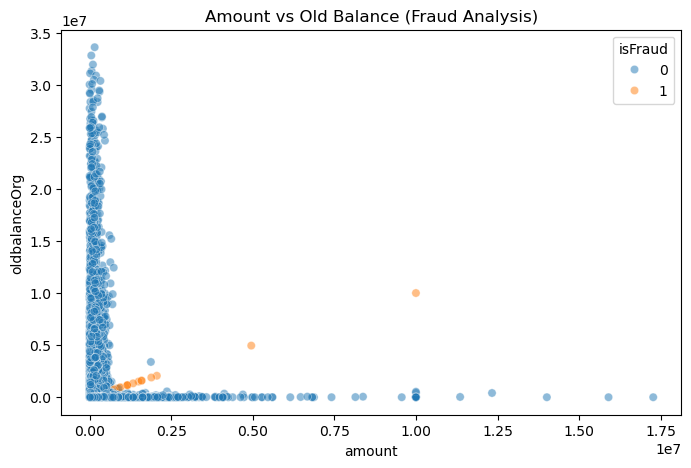

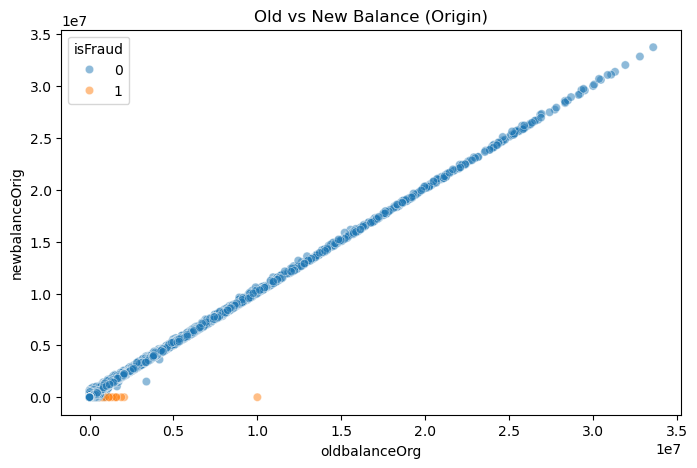

In [11]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='amount', y='oldbalanceOrg', hue='isFraud', data=scatter_df, alpha=0.5)
plt.title('Amount vs Old Balance (Fraud Analysis)')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(x='oldbalanceOrg', y='newbalanceOrig', hue='isFraud', data=scatter_df, alpha=0.5)
plt.title('Old vs New Balance (Origin)')
plt.show()

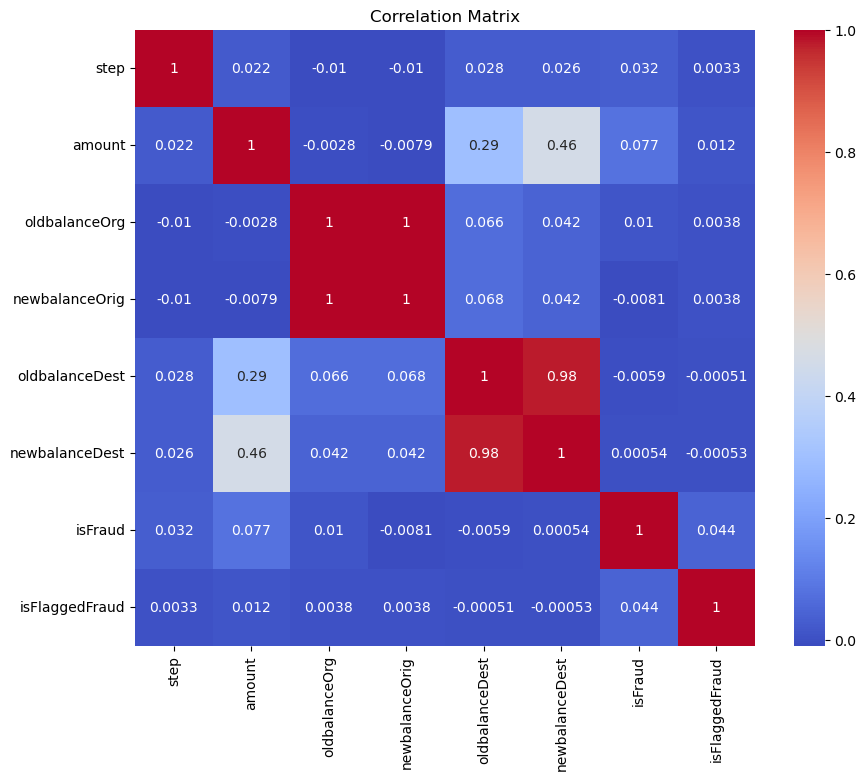

In [12]:
plt.figure(figsize=(10,8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [13]:
df.corr(numeric_only=True)['isFraud'].sort_values(ascending=False)

isFraud           1.000000
amount            0.076688
isFlaggedFraud    0.044109
step              0.031578
oldbalanceOrg     0.010154
newbalanceDest    0.000535
oldbalanceDest   -0.005885
newbalanceOrig   -0.008148
Name: isFraud, dtype: float64

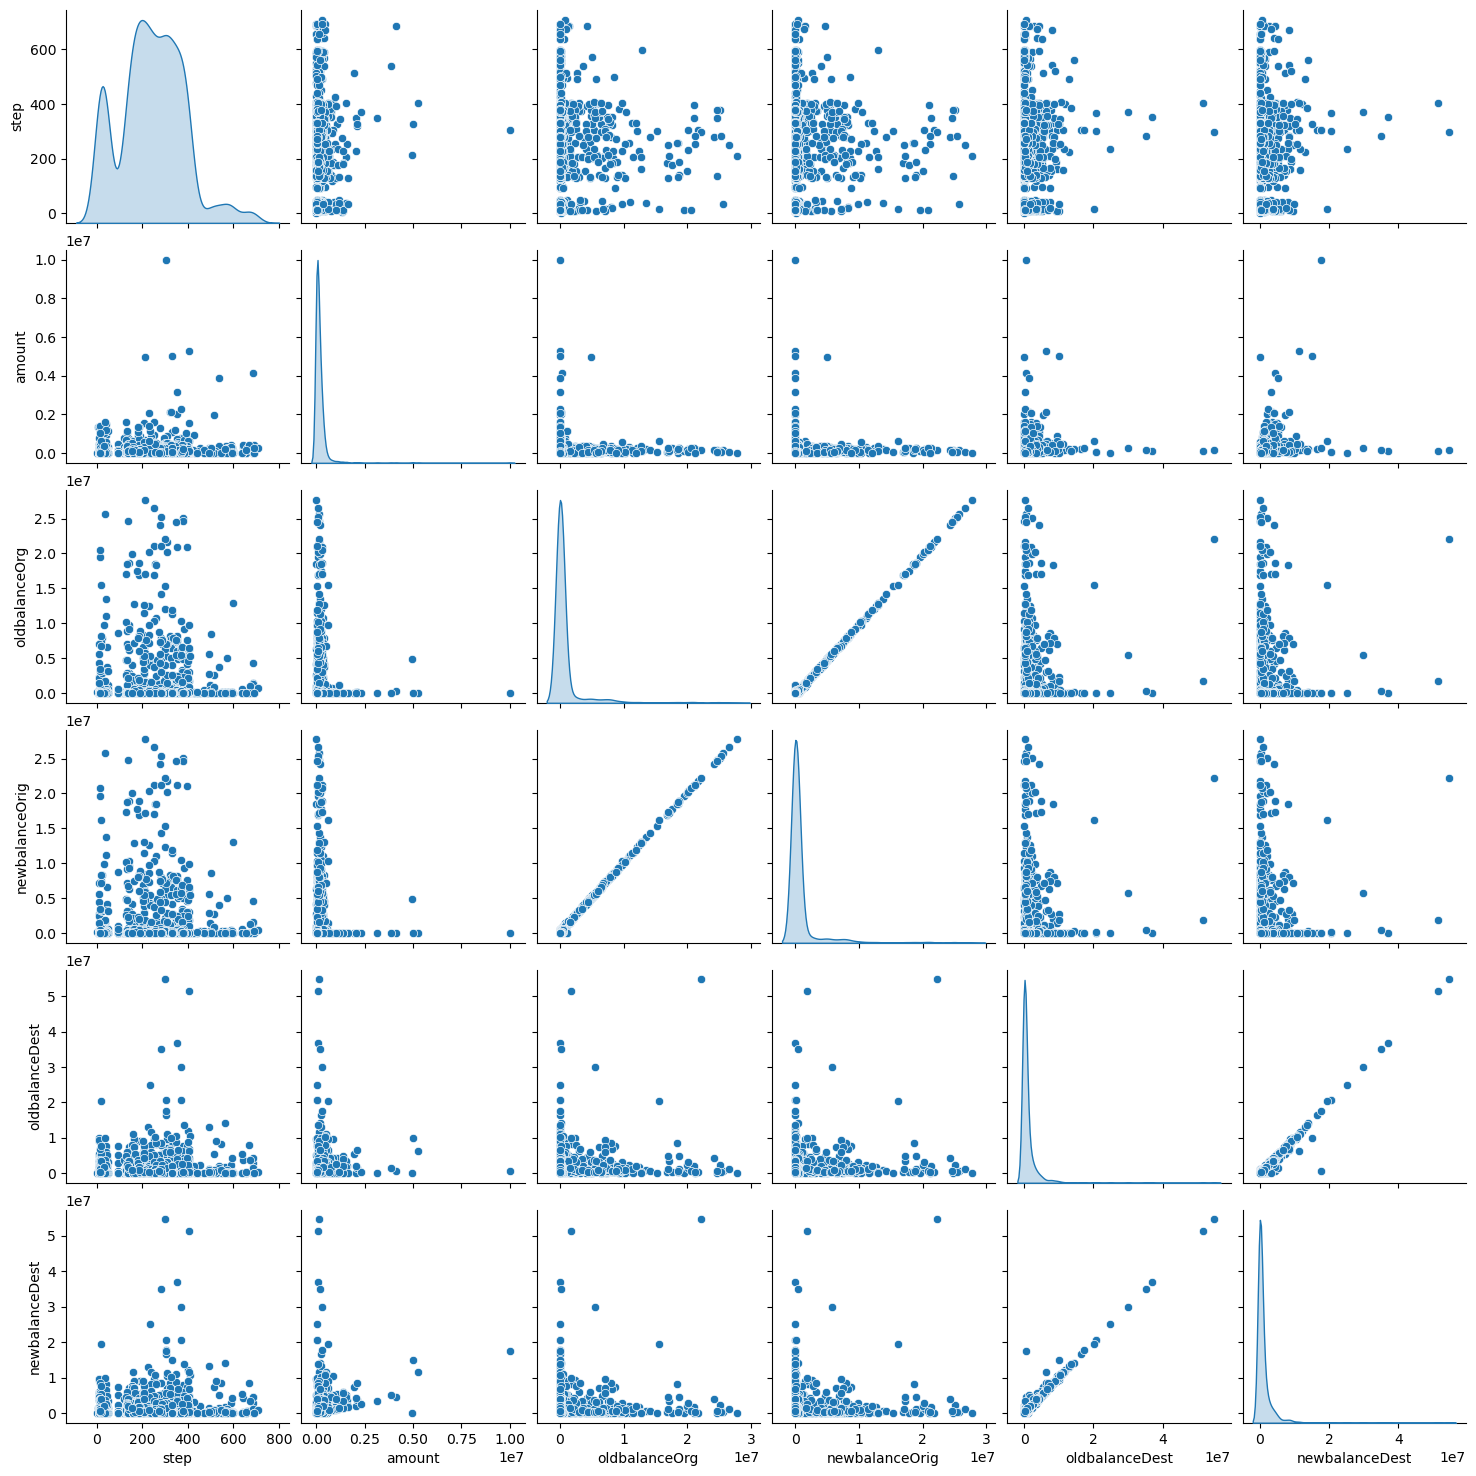

In [14]:
numerical_cols = [
    'step',
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest'
]

sns.pairplot(pairplot_df[numerical_cols], diag_kind='kde')
plt.show()

In [15]:
df['isFraud'].value_counts(normalize=True) * 100

isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64